# EA-TTM — Supervisor-Requested Line Charts

**Purpose:** Regenerate the key discussion/presentation figures as line charts for a 10-minute defense.

## Presentation simplification

Only the four models required for the main research story are retained:

1. Weekly Seasonal Naive
2. Zero-shot TTM
3. Frozen HP-TTM
4. Primary EA-TTM

The following ablation models are intentionally excluded from the **main presentation figures**:

- Retail-only gated adapter
- Ungated cross-feed adapter

Their results remain preserved in the project artifacts and can still be discussed if the panel asks about ablations.

## Governance

This notebook performs **no model training, tuning, checkpoint switching, or test re-evaluation**. It only reads locked Phase 10–12 result files and creates new visualizations.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Project paths and preflight

In [2]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/EA_TTM_RETAIL")
METADATA_DIR = PROJECT_ROOT / "metadata"
RESULTS_TABLE_DIR = PROJECT_ROOT / "results" / "tables"
RESULTS_FIGURE_DIR = PROJECT_ROOT / "results" / "figures"
OUTPUT_DIR = RESULTS_FIGURE_DIR / "14R_supervisor_line_charts"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required_artifacts = {
    "phase10_summary": METADATA_DIR / "10_RUN_SUMMARY.json",
    "development_lock": METADATA_DIR / "09_MODEL_DEVELOPMENT_LOCK.json",
    "final_evaluation_lock": METADATA_DIR / "10_FINAL_EVALUATION_LOCK.json",
    "master_results": RESULTS_TABLE_DIR / "11_MASTER_RESULTS_TABLE.csv",
    "horizon_metrics": RESULTS_TABLE_DIR / "11B_FINAL_TEST_HORIZON_METRICS.csv",
    "primary_vs_hp_horizon": RESULTS_TABLE_DIR / "11B_PRIMARY_VS_HP_HORIZON_COMPARISON.csv",
}

missing = [
    str(path)
    for path in required_artifacts.values()
    if not path.exists()
]

assert not missing, (
    "Required locked artifacts are missing: "
    + "; ".join(missing)
)

Mounted at /content/drive


## Verify experiment lock

In [3]:
def load_json(path: Path):
    return json.loads(path.read_text(encoding="utf-8"))

phase10 = load_json(METADATA_DIR / "10_RUN_SUMMARY.json")
development_lock = load_json(METADATA_DIR / "09_MODEL_DEVELOPMENT_LOCK.json")
final_evaluation_lock = load_json(METADATA_DIR / "10_FINAL_EVALUATION_LOCK.json")

assert development_lock["post_lock_tuning_permitted"] is False
assert final_evaluation_lock["post_test_tuning_permitted"] is False
assert final_evaluation_lock["test_results_may_change_model_selection"] is False
assert development_lock["primary_model"] == "Phase 08 best-balanced EA-TTM"
assert int(development_lock["primary_epoch"]) == 15

print("Primary model:", development_lock["primary_model"])
print("Primary epoch:", development_lock["primary_epoch"])
print("Post-test tuning permitted:", False)

Primary model: Phase 08 best-balanced EA-TTM
Primary epoch: 15
Post-test tuning permitted: False


## Load locked results

In [4]:
master_results = pd.read_csv(
    RESULTS_TABLE_DIR / "11_MASTER_RESULTS_TABLE.csv"
)

horizon_metrics = pd.read_csv(
    RESULTS_TABLE_DIR / "11B_FINAL_TEST_HORIZON_METRICS.csv"
)

primary_vs_hp_horizon = pd.read_csv(
    RESULTS_TABLE_DIR / "11B_PRIMARY_VS_HP_HORIZON_COMPARISON.csv"
)

MAIN_MODELS = [
    "Weekly Seasonal Naive",
    "Zero-shot TTM",
    "Frozen HP-TTM",
    "Primary EA-TTM",
]

SHORT_NAMES = {
    "Weekly Seasonal Naive": "Seasonal Naive",
    "Zero-shot TTM": "Zero-shot TTM",
    "Frozen HP-TTM": "HP-TTM",
    "Primary EA-TTM": "EA-TTM",
}

main_results = (
    master_results
    .set_index("model")
    .loc[MAIN_MODELS]
    .reset_index()
)

main_results["display_name"] = (
    main_results["model"].map(SHORT_NAMES)
)

assert len(main_results) == 4
assert set(primary_vs_hp_horizon["horizon"]) == set(range(1, 29))

main_results

,model,mse,rmse,mae,wape,normal_mse,extreme_mse,positive_extreme_mse,negative_extreme_mse,display_name
0,Weekly Seasonal Naive,7.165766,2.676895,1.243972,0.862181,4.466177,50.009881,49.857236,52.231786,Seasonal Naive
1,Zero-shot TTM,4.637857,2.153569,1.041414,0.721791,2.107093,44.802609,44.702207,46.264069,Zero-shot TTM
2,Frozen HP-TTM,4.563047,2.136129,1.028902,0.713119,2.067278,44.172408,44.064259,45.746637,HP-TTM
3,Primary EA-TTM,4.528610,2.128053,1.037919,0.719369,2.082416,43.351182,43.126123,46.627155,EA-TTM


# Main presentation figures

These figures are designed for the **10-minute presentation**. The story is deliberately reduced to:

**Seasonal Naive → Zero-shot TTM → HP-TTM → EA-TTM**

## Figure 1 — Model progression: overall MSE

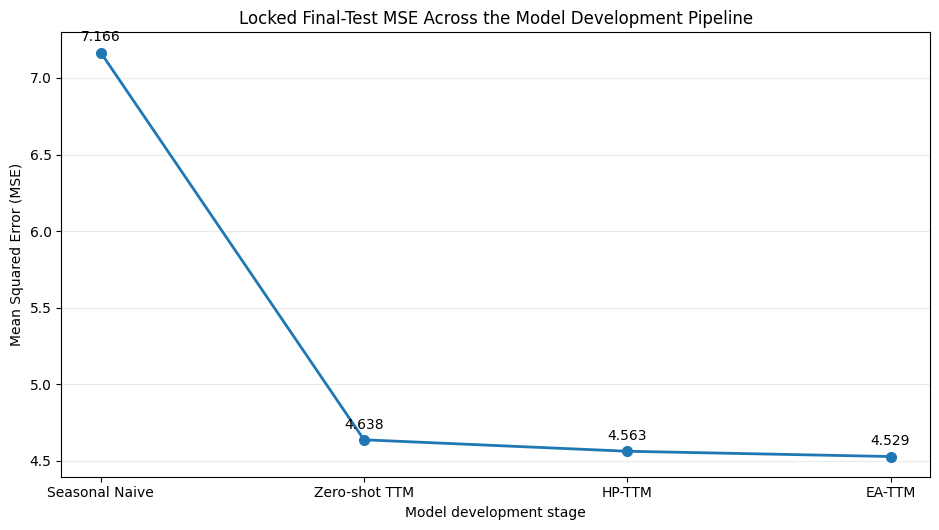

In [5]:
FIG01 = OUTPUT_DIR / "14R_FIG01_MODEL_PROGRESSION_MSE.png"

fig, ax = plt.subplots(figsize=(9.5, 5.4))

ax.plot(
    main_results["display_name"],
    main_results["mse"],
    marker="o",
    linewidth=2.0,
    markersize=7,
)

for x_value, y_value in zip(
    main_results["display_name"],
    main_results["mse"],
):
    ax.annotate(
        f"{y_value:.3f}",
        (x_value, y_value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=10,
    )

ax.set_ylabel("Mean Squared Error (MSE)")
ax.set_xlabel("Model development stage")
ax.set_title(
    "Locked Final-Test MSE Across the Model Development Pipeline"
)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(FIG01, dpi=240, bbox_inches="tight")
plt.show()

## Figure 2 — HP-TTM vs EA-TTM by demand regime

This figure focuses directly on the research question: does the proposed EA-TTM improve the retail-adapted TTM?

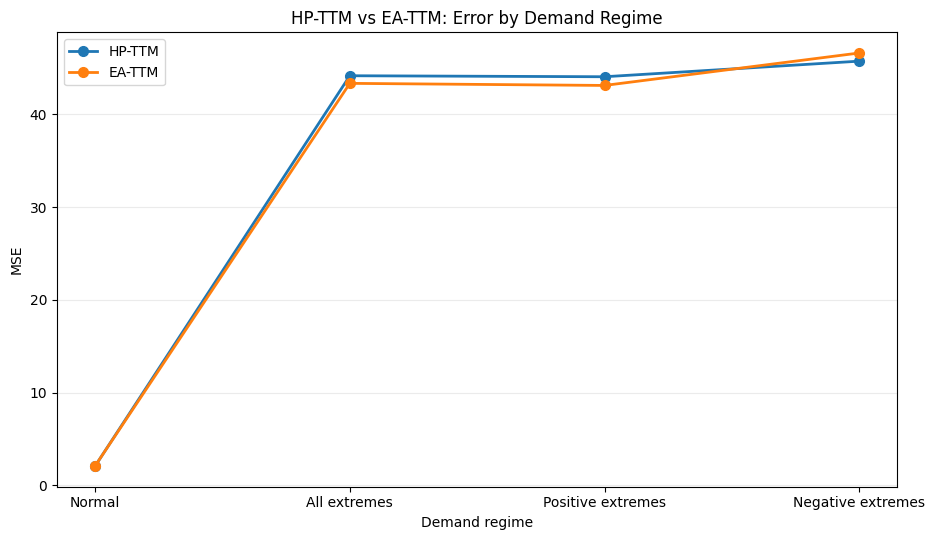

In [6]:
FIG02 = OUTPUT_DIR / "14R_FIG02_HP_VS_EA_REGIME_MSE.png"

indexed_results = master_results.set_index("model")
hp = indexed_results.loc["Frozen HP-TTM"]
ea = indexed_results.loc["Primary EA-TTM"]

regime_labels = [
    "Normal",
    "All extremes",
    "Positive extremes",
    "Negative extremes",
]

hp_values = [
    hp["normal_mse"],
    hp["extreme_mse"],
    hp["positive_extreme_mse"],
    hp["negative_extreme_mse"],
]

ea_values = [
    ea["normal_mse"],
    ea["extreme_mse"],
    ea["positive_extreme_mse"],
    ea["negative_extreme_mse"],
]

fig, ax = plt.subplots(figsize=(9.5, 5.5))

ax.plot(
    regime_labels,
    hp_values,
    marker="o",
    linewidth=2.0,
    markersize=7,
    label="HP-TTM",
)

ax.plot(
    regime_labels,
    ea_values,
    marker="o",
    linewidth=2.0,
    markersize=7,
    label="EA-TTM",
)

ax.set_ylabel("MSE")
ax.set_xlabel("Demand regime")
ax.set_title("HP-TTM vs EA-TTM: Error by Demand Regime")
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(FIG02, dpi=240, bbox_inches="tight")
plt.show()

## Figure 3 — Percentage change of EA-TTM relative to HP-TTM

Positive values mean EA-TTM reduced error. Negative values mean EA-TTM produced higher error.

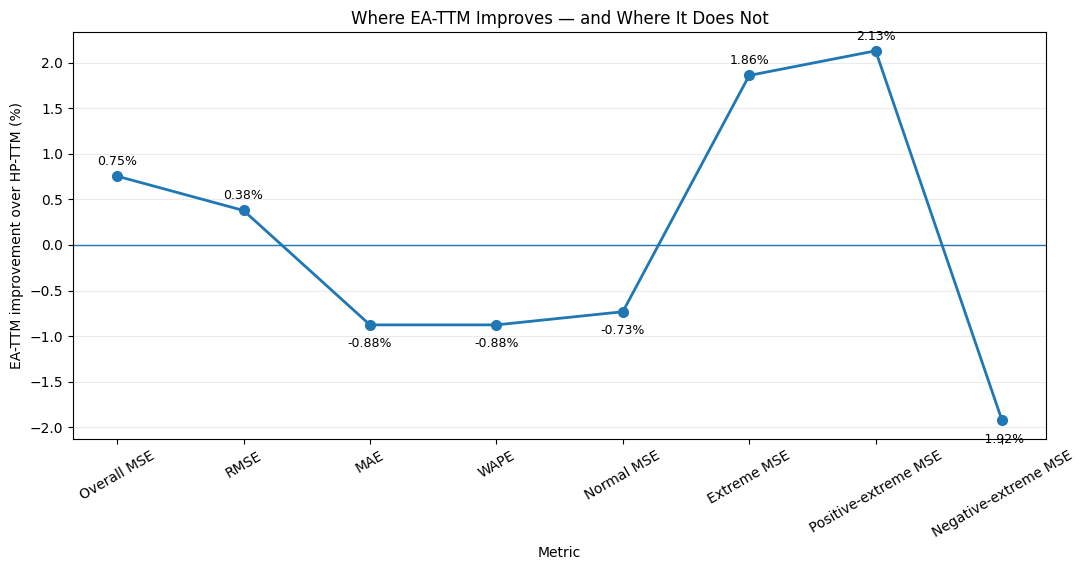

In [7]:
FIG03 = OUTPUT_DIR / "14R_FIG03_EA_VS_HP_PERCENT_CHANGE_LINE.png"

comparison_labels = [
    "Overall MSE",
    "RMSE",
    "MAE",
    "WAPE",
    "Normal MSE",
    "Extreme MSE",
    "Positive-extreme MSE",
    "Negative-extreme MSE",
]

comparison_values = [
    phase10["primary_ea_vs_hp_percent"]["overall_mse_improvement_percent"],
    phase10["primary_ea_vs_hp_percent"]["overall_rmse_improvement_percent"],
    phase10["primary_ea_vs_hp_percent"]["overall_mae_improvement_percent"],
    phase10["primary_ea_vs_hp_percent"]["overall_wape_improvement_percent"],
    phase10["primary_ea_vs_hp_percent"]["normal_mse_improvement_percent"],
    phase10["primary_ea_vs_hp_percent"]["extreme_mse_improvement_percent"],
    phase10["primary_ea_vs_hp_percent"]["positive_extreme_mse_improvement_percent"],
    phase10["primary_ea_vs_hp_percent"]["negative_extreme_mse_improvement_percent"],
]

fig, ax = plt.subplots(figsize=(11, 5.8))

ax.plot(
    comparison_labels,
    comparison_values,
    marker="o",
    linewidth=2.0,
    markersize=7,
)

ax.axhline(0.0, linewidth=1.0)

for x_value, y_value in zip(
    comparison_labels,
    comparison_values,
):
    ax.annotate(
        f"{y_value:.2f}%",
        (x_value, y_value),
        xytext=(0, 8 if y_value >= 0 else -16),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

ax.set_ylabel("EA-TTM improvement over HP-TTM (%)")
ax.set_xlabel("Metric")
ax.set_title("Where EA-TTM Improves — and Where It Does Not")
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(FIG03, dpi=240, bbox_inches="tight")
plt.show()

# Horizon figures

The 28-day graphs compare only **HP-TTM and EA-TTM**. This keeps the audience focused on the contribution of the proposed model.

## Figure 4 — HP-TTM vs EA-TTM overall MSE across the 28-day horizon

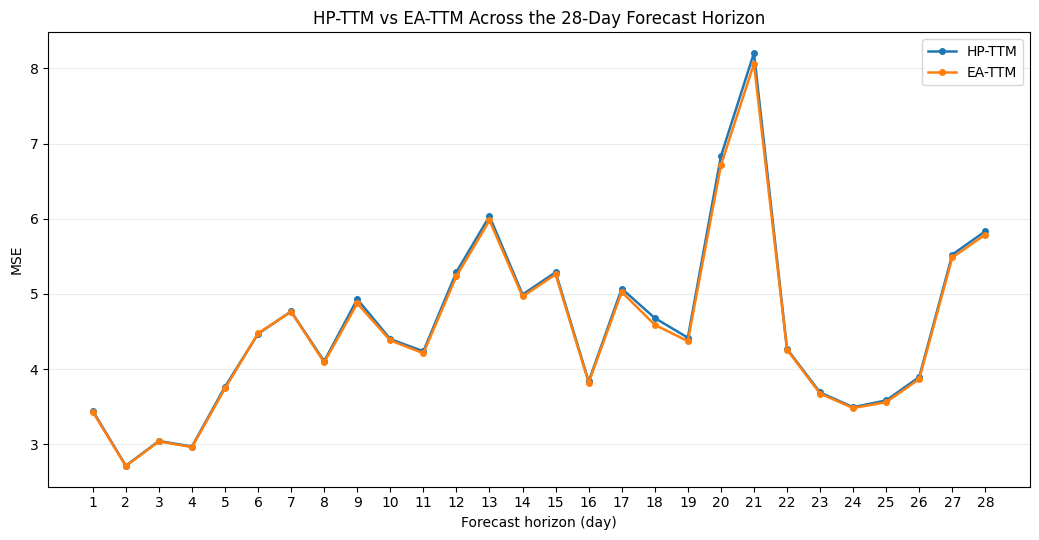

In [8]:
FIG04 = OUTPUT_DIR / "14R_FIG04_HP_VS_EA_28DAY_MSE.png"

hp_horizon = (
    horizon_metrics.loc[
        horizon_metrics["model"] == "Frozen HP-TTM"
    ]
    .sort_values("horizon")
)

ea_horizon = (
    horizon_metrics.loc[
        horizon_metrics["model"] == "Primary EA-TTM"
    ]
    .sort_values("horizon")
)

fig, ax = plt.subplots(figsize=(10.5, 5.5))

ax.plot(
    hp_horizon["horizon"],
    hp_horizon["mse"],
    marker="o",
    linewidth=1.8,
    markersize=4,
    label="HP-TTM",
)

ax.plot(
    ea_horizon["horizon"],
    ea_horizon["mse"],
    marker="o",
    linewidth=1.8,
    markersize=4,
    label="EA-TTM",
)

ax.set_xlabel("Forecast horizon (day)")
ax.set_ylabel("MSE")
ax.set_title("HP-TTM vs EA-TTM Across the 28-Day Forecast Horizon")
ax.set_xticks(np.arange(1, 29))
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(FIG04, dpi=240, bbox_inches="tight")
plt.show()

## Figure 5 — HP-TTM vs EA-TTM extreme MSE across the 28-day horizon

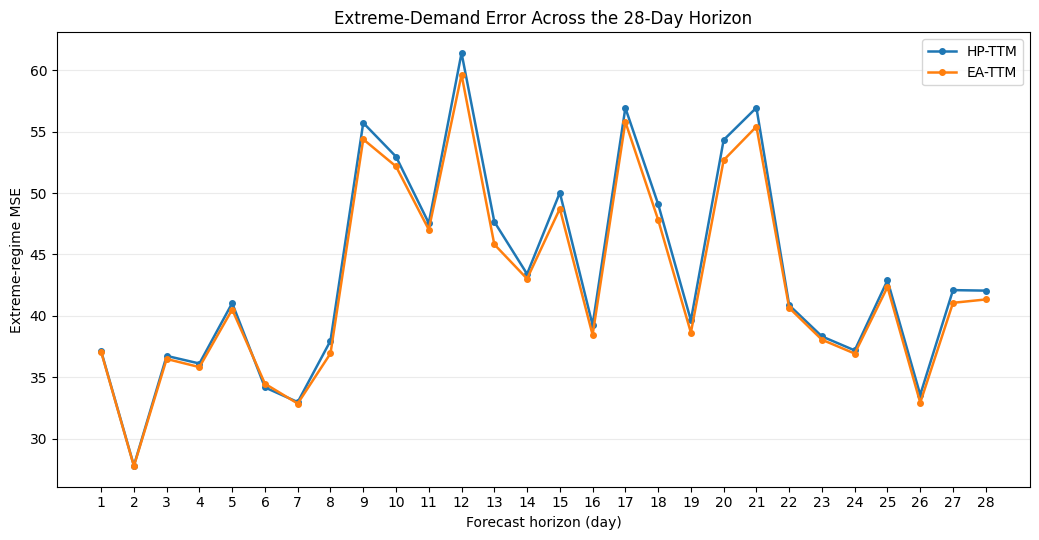

In [9]:
FIG05 = OUTPUT_DIR / "14R_FIG05_HP_VS_EA_28DAY_EXTREME_MSE.png"

fig, ax = plt.subplots(figsize=(10.5, 5.5))

ax.plot(
    hp_horizon["horizon"],
    hp_horizon["extreme_mse"],
    marker="o",
    linewidth=1.8,
    markersize=4,
    label="HP-TTM",
)

ax.plot(
    ea_horizon["horizon"],
    ea_horizon["extreme_mse"],
    marker="o",
    linewidth=1.8,
    markersize=4,
    label="EA-TTM",
)

ax.set_xlabel("Forecast horizon (day)")
ax.set_ylabel("Extreme-regime MSE")
ax.set_title("Extreme-Demand Error Across the 28-Day Horizon")
ax.set_xticks(np.arange(1, 29))
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(FIG05, dpi=240, bbox_inches="tight")
plt.show()

## Figure 6 — EA-TTM improvement over HP-TTM across the 28-day horizon

This is the most direct horizon graph for a short presentation. The zero line immediately shows whether EA-TTM improved or worsened at each day.

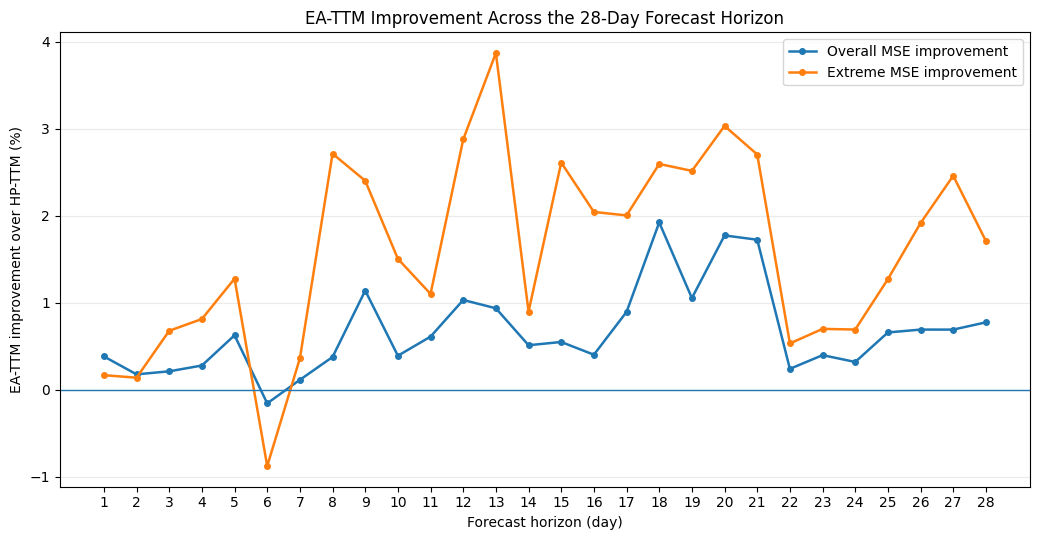

In [10]:
FIG06 = OUTPUT_DIR / "14R_FIG06_EA_VS_HP_28DAY_IMPROVEMENT.png"

horizon_comparison = (
    primary_vs_hp_horizon.sort_values("horizon")
)

fig, ax = plt.subplots(figsize=(10.5, 5.5))

ax.plot(
    horizon_comparison["horizon"],
    horizon_comparison["mse_improvement_percent"],
    marker="o",
    linewidth=1.8,
    markersize=4,
    label="Overall MSE improvement",
)

ax.plot(
    horizon_comparison["horizon"],
    horizon_comparison["extreme_mse_improvement_percent"],
    marker="o",
    linewidth=1.8,
    markersize=4,
    label="Extreme MSE improvement",
)

ax.axhline(0.0, linewidth=1.0)
ax.set_xlabel("Forecast horizon (day)")
ax.set_ylabel("EA-TTM improvement over HP-TTM (%)")
ax.set_title("EA-TTM Improvement Across the 28-Day Forecast Horizon")
ax.set_xticks(np.arange(1, 29))
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(FIG06, dpi=240, bbox_inches="tight")
plt.show()

# Backup / limitation figures

These are generated for completeness but are not intended to consume presentation time unless the panel asks.

## Figure 7 — MAE across the four-model development pipeline

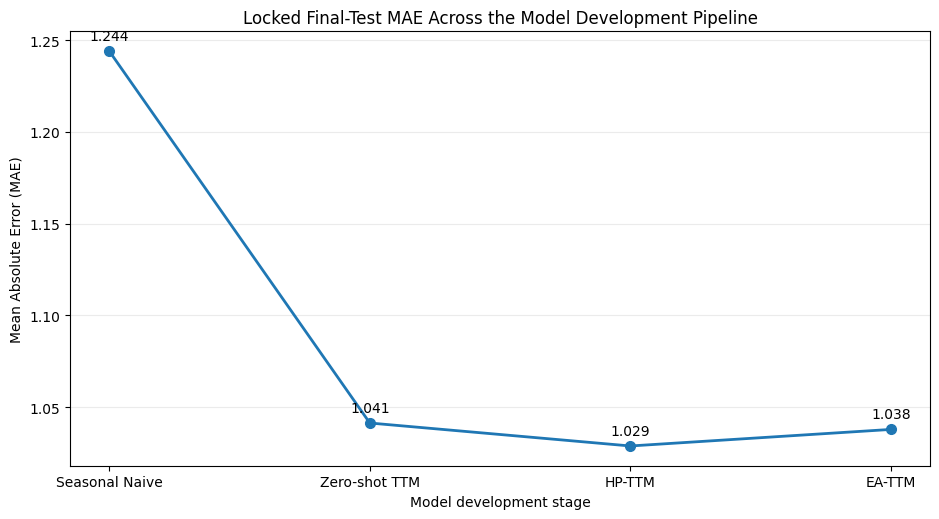

In [11]:
FIG07 = OUTPUT_DIR / "14R_FIG07_MODEL_PROGRESSION_MAE_BACKUP.png"

fig, ax = plt.subplots(figsize=(9.5, 5.3))

ax.plot(
    main_results["display_name"],
    main_results["mae"],
    marker="o",
    linewidth=2.0,
    markersize=7,
)

for x_value, y_value in zip(
    main_results["display_name"],
    main_results["mae"],
):
    ax.annotate(
        f"{y_value:.3f}",
        (x_value, y_value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=10,
    )

ax.set_ylabel("Mean Absolute Error (MAE)")
ax.set_xlabel("Model development stage")
ax.set_title("Locked Final-Test MAE Across the Model Development Pipeline")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(FIG07, dpi=240, bbox_inches="tight")
plt.show()

## Figure 8 — WAPE across the four-model development pipeline

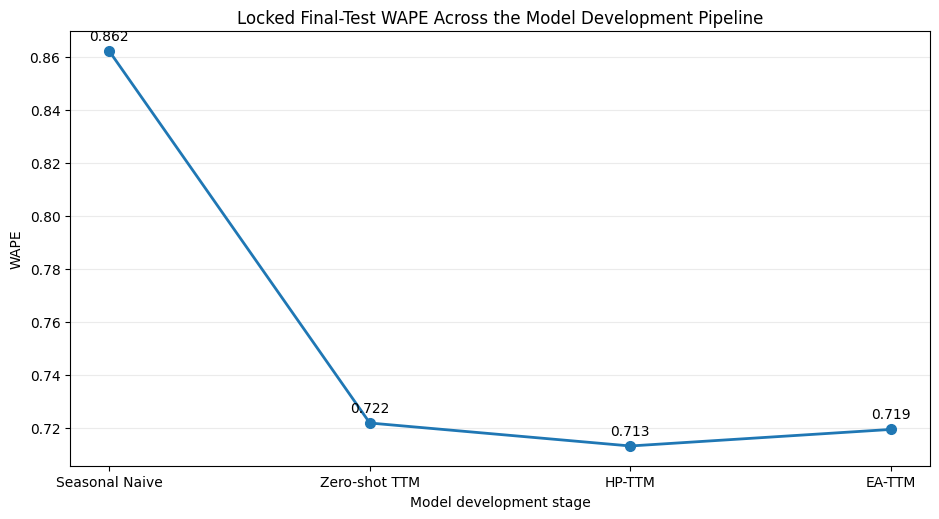

In [12]:
FIG08 = OUTPUT_DIR / "14R_FIG08_MODEL_PROGRESSION_WAPE_BACKUP.png"

fig, ax = plt.subplots(figsize=(9.5, 5.3))

ax.plot(
    main_results["display_name"],
    main_results["wape"],
    marker="o",
    linewidth=2.0,
    markersize=7,
)

for x_value, y_value in zip(
    main_results["display_name"],
    main_results["wape"],
):
    ax.annotate(
        f"{y_value:.3f}",
        (x_value, y_value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=10,
    )

ax.set_ylabel("WAPE")
ax.set_xlabel("Model development stage")
ax.set_title("Locked Final-Test WAPE Across the Model Development Pipeline")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(FIG08, dpi=240, bbox_inches="tight")
plt.show()

## Presentation graph summary

In [13]:
summary = {
    "main_models": MAIN_MODELS,
    "excluded_from_main_presentation": [
        "Retail-only gated adapter",
        "Ungated cross-feed adapter",
    ],
    "main_figures": {
        "model_progression_mse": str(FIG01),
        "hp_vs_ea_regime_mse": str(FIG02),
        "ea_vs_hp_percent_change": str(FIG03),
        "hp_vs_ea_28day_mse": str(FIG04),
        "hp_vs_ea_28day_extreme_mse": str(FIG05),
        "ea_vs_hp_28day_improvement": str(FIG06),
    },
    "backup_figures": {
        "model_progression_mae": str(FIG07),
        "model_progression_wape": str(FIG08),
    },
    "key_results": {
        "overall_mse_improvement_percent": (
            phase10["primary_ea_vs_hp_percent"][
                "overall_mse_improvement_percent"
            ]
        ),
        "extreme_mse_improvement_percent": (
            phase10["primary_ea_vs_hp_percent"][
                "extreme_mse_improvement_percent"
            ]
        ),
        "positive_extreme_mse_improvement_percent": (
            phase10["primary_ea_vs_hp_percent"][
                "positive_extreme_mse_improvement_percent"
            ]
        ),
        "overall_mse_improved_horizons": int(
            (
                primary_vs_hp_horizon[
                    "mse_improvement_percent"
                ] > 0.0
            ).sum()
        ),
        "extreme_mse_improved_horizons": int(
            (
                primary_vs_hp_horizon[
                    "extreme_mse_improvement_percent"
                ] > 0.0
            ).sum()
        ),
    },
    "post_test_tuning_permitted": False,
}

MANIFEST_PATH = (
    METADATA_DIR
    / "14R_SUPERVISOR_LINE_CHART_MANIFEST.json"
)

MANIFEST_PATH.write_text(
    json.dumps(
        summary,
        indent=2,
    ),
    encoding="utf-8",
)

SUMMARY_MD_PATH = (
    PROJECT_ROOT
    / "results"
    / "14R_PRESENTATION_GRAPH_SUMMARY.md"
)

summary_lines = [
    "# Supervisor-Requested Presentation Graphs",
    "",
    "## Main story",
    "",
    "Seasonal Naive -> Zero-shot TTM -> HP-TTM -> EA-TTM",
    "",
    "## Models removed from the main presentation figures",
    "",
    "- Retail-only gated adapter",
    "- Ungated cross-feed adapter",
    "",
    "Their experimental results remain preserved for backup discussion.",
    "",
    "## Main presentation figures",
    "",
    "1. Four-model overall MSE progression",
    "2. HP-TTM vs EA-TTM regime MSE",
    "3. EA-TTM percentage change vs HP-TTM",
    "4. HP-TTM vs EA-TTM 28-day overall MSE",
    "5. HP-TTM vs EA-TTM 28-day extreme MSE",
    "6. EA-TTM overall/extreme MSE improvement by horizon",
    "",
    "## Suggested 10-minute usage",
    "",
    "Use Figures 1, 2, and 6 in the main presentation.",
    "Keep Figures 3, 4, 5, 7, and 8 as supporting or backup evidence.",
]

SUMMARY_MD_PATH.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)

705

## Return block

After a successful run, return only this block to ChatGPT.

In [14]:
return_block = {
    "status": "PHASE_14R_SUPERVISOR_LINE_CHARTS_COMPLETE",
    "main_models": MAIN_MODELS,
    "excluded_from_main_presentation": [
        "Retail-only gated adapter",
        "Ungated cross-feed adapter",
    ],
    "main_figures": summary["main_figures"],
    "backup_figures": summary["backup_figures"],
    "key_results": summary["key_results"],
    "manifest": str(MANIFEST_PATH),
    "summary_document": str(SUMMARY_MD_PATH),
    "post_test_tuning_permitted": False,
}

print("PHASE 14R RETURN BLOCK")
print(
    json.dumps(
        return_block,
        indent=2,
    )
)

PHASE 14R RETURN BLOCK
{
  "status": "PHASE_14R_SUPERVISOR_LINE_CHARTS_COMPLETE",
  "main_models": [
    "Weekly Seasonal Naive",
    "Zero-shot TTM",
    "Frozen HP-TTM",
    "Primary EA-TTM"
  ],
  "excluded_from_main_presentation": [
    "Retail-only gated adapter",
    "Ungated cross-feed adapter"
  ],
  "main_figures": {
    "model_progression_mse": "/content/drive/MyDrive/EA_TTM_RETAIL/results/figures/14R_supervisor_line_charts/14R_FIG01_MODEL_PROGRESSION_MSE.png",
    "hp_vs_ea_regime_mse": "/content/drive/MyDrive/EA_TTM_RETAIL/results/figures/14R_supervisor_line_charts/14R_FIG02_HP_VS_EA_REGIME_MSE.png",
    "ea_vs_hp_percent_change": "/content/drive/MyDrive/EA_TTM_RETAIL/results/figures/14R_supervisor_line_charts/14R_FIG03_EA_VS_HP_PERCENT_CHANGE_LINE.png",
    "hp_vs_ea_28day_mse": "/content/drive/MyDrive/EA_TTM_RETAIL/results/figures/14R_supervisor_line_charts/14R_FIG04_HP_VS_EA_28DAY_MSE.png",
    "hp_vs_ea_28day_extreme_mse": "/content/drive/MyDrive/EA_TTM_RETAIL/results/f